# RFM vs. FM on a plain translation

**Contents.** A sanity check without any geometry: one Gaussian is transported to a translated copy of itself in the flat plane. Both clouds lie well inside a larger disc, which only serves as the domain on which the graph for RFM is built.
1. Biharmonic geometry of the disc: how far the biharmonic distance and the raw RFM field are from Euclidean ones.
2. Biharmonic vs. Euclidean OT couplings against the exact OT map (the translation).
3. Training the 2 × 2 grid Riemannian/Euclidean FM × biharmonic/Euclidean coupling; endpoints, learned fields and paths.
4. FM/RFM conditional reference paths vs. the exact geodesics, which here are straight lines.

The domain is convex and flat, so every geodesic is a straight chord and the exact OT map between the clouds is the translation $x\mapsto x+(\mu_1-\mu_0)$. Euclidean FM with Euclidean OT is therefore already exact in the limit; RFM can only match it. Any deviation of the RFM models shows the bias introduced by the graph-based geometry itself.

The code reuses the `riemannian_toys` package (run the notebook from `docs/notebooks`); the domain is `riemannian_toys.disc.Disc`.

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
import pandas as pd
from IPython.display import display
from scipy.spatial.distance import cdist

from ott.geometry import costs

from cellflow.ode_solver import RFMInterpolation
from cellflow.utils import match_linear
from riemannian_toys import comparison, flows, kernels, loss_modes, plotting, reference_paths
from riemannian_toys.disc import Disc

/home/markus/university/adlr/CellFlow/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data

The graph is built on 5,000 area-uniform samples of a disc of radius 4. The source is an isotropic Gaussian with variance 0.25 centered at $(-1.5, 0)$, the target the same Gaussian centered at $(1.5, 0)$. Both are conditioned on the disc, which removes practically nothing: their means are 2.5 radii (5 standard deviations) away from the boundary circle.

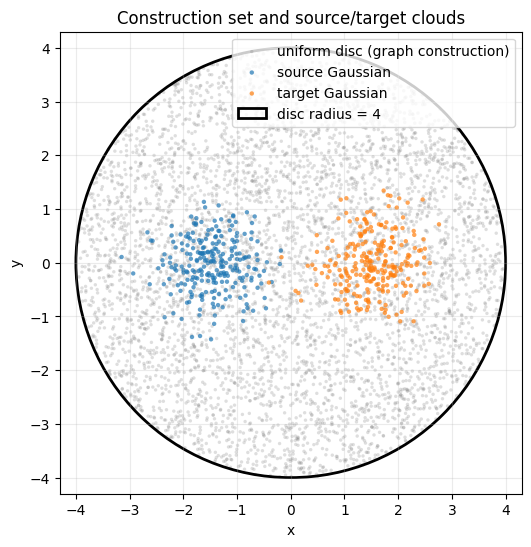

In [2]:
disc = Disc(radius=4.0)
construction_points = disc.sample_uniform(5_000, np.random.default_rng(42)).astype(np.float32)

variance = 0.25
n_points_per_gaussian = 250
mean_source = np.array([-1.5, 0.0])
mean_target = np.array([1.5, 0.0])
translation = mean_target - mean_source
rng = np.random.default_rng(123)
source = disc.sample_gaussian(mean_source, variance, n_points_per_gaussian, rng)[0].astype(np.float32)
target = disc.sample_gaussian(mean_target, variance, n_points_per_gaussian, rng)[0].astype(np.float32)

plotting.plot_point_clouds(disc, [
    (construction_points, {"s": 6, "alpha": 0.25, "edgecolors": "none", "color": "tab:gray",
                           "label": "uniform disc (graph construction)"}),
    (source, {"s": 10, "alpha": 0.7, "edgecolors": "none", "color": "tab:blue", "label": "source Gaussian"}),
    (target, {"s": 10, "alpha": 0.7, "edgecolors": "none", "color": "tab:orange", "label": "target Gaussian"}),
], "Construction set and source/target clouds", figsize=(6.5, 6), label_boundaries=True)

## Biharmonic geometry of the disc

The geometry uses the same settings as the annulus notebook: fixed-bandwidth Gaussian kernel on a CkNN support ($k_\rho=24$, $\delta=2$), unnormalized Laplacian $L=D-W$, 32 biharmonic modes $\Psi_k(x)=\phi_k(x)/\lambda_k$ and their continuous Nyström extension.

On a flat convex domain the ideal distance is the Euclidean one. The biharmonic distance is not: it is a smooth function of the leading Laplacian eigenfunctions of the *bounded* disc, so it is compressed near the boundary and saturates for distant points. The cell below compares the two on pairs of points from the region the clouds occupy, and shows the raw RFM conditional field $u_t(x\mid x_1)=-\frac{d(x,x_1)}{1-t}\,\frac{\nabla_x d(x,x_1)}{\|\nabla_x d(x,x_1)\|^2}$ towards the target mean. Its ideal counterpart is the straight field pointing at $x_1$; the colors show the angle between the two.

fixed Gaussian: fitted in 1.44s


,edges,components,min_degree,median_degree,lambda_2,max_eigen_residual,extension_relative_error,fit_seconds
kernel,,,,,,,,
fixed Gaussian,228875,1,7.125166,23.223075,0.08353,3.512369e-10,1.016645e-07,1.44367


,median_angle_deg,p90_angle_deg,median_speed_ratio
grid points near the source mean,9.167868,18.221928,1.451017
whole disc,10.449465,26.408670,1.732207


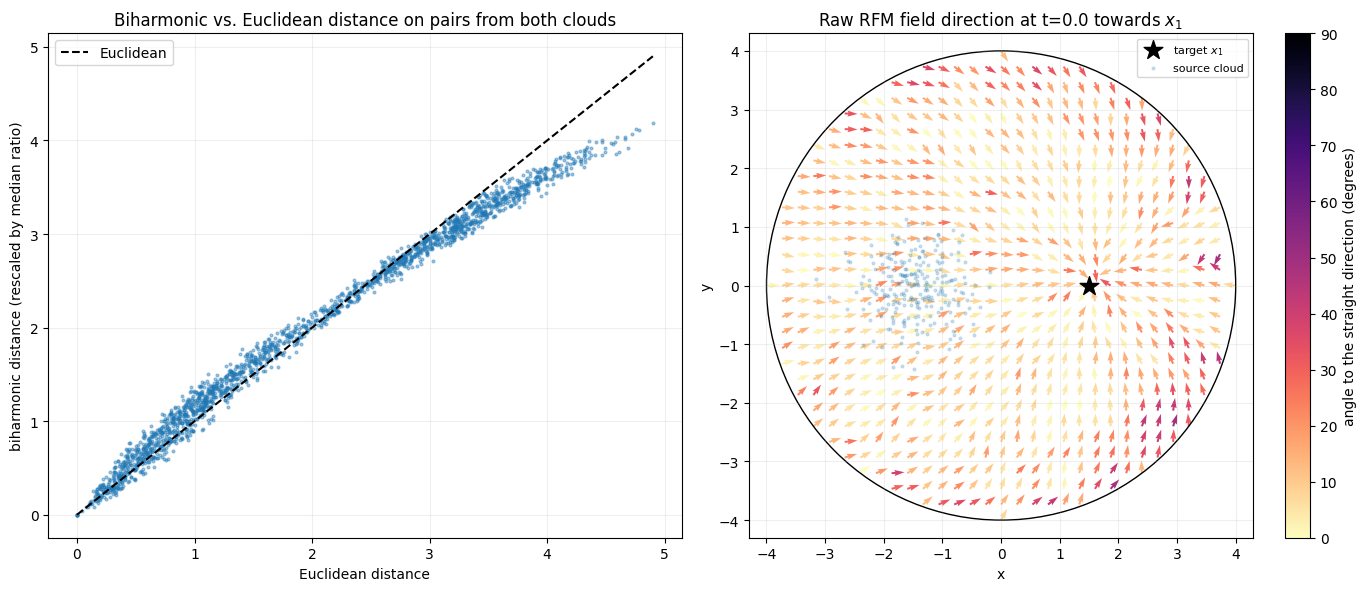

In [3]:
kernel_models, _, _, kernel_fit_df = kernels.fit_kernel_profiles(
    construction_points, {"fixed Gaussian": "fixed_gaussian"}, density_k=24, delta=2.0, n_modes=32,
    laplacian_type="unnormalized", spectral_weight_type="biharmonic",
)
nystroem = kernel_models["fixed Gaussian"]
display(kernel_fit_df)
embed = jax.jit(jax.vmap(nystroem.extend_point))

# Biharmonic vs. Euclidean distance on random pairs from the transport region.
pair_rng = np.random.default_rng(7)
region = np.vstack((source, target))
pair_a = region[pair_rng.integers(len(region), size=2000)]
pair_b = region[pair_rng.integers(len(region), size=2000)]
d_euclidean = np.linalg.norm(pair_a - pair_b, axis=1)
d_biharmonic = np.linalg.norm(np.asarray(embed(jnp.asarray(pair_a))) - np.asarray(embed(jnp.asarray(pair_b))), axis=1)

# Raw RFM field towards the target mean, compared to the straight direction.
field_target = mean_target.astype(np.float32)
field_time = 0.0
field_grid = disc.learned_field_grid(31)
field_grid = field_grid[np.linalg.norm(field_grid - field_target, axis=1) > 0.15]
raw_interpolator = RFMInterpolation(nystroem, project_to_manifold=False)
raw_field = np.asarray(jax.jit(raw_interpolator.u_t)(
    jnp.asarray(field_grid), jnp.broadcast_to(jnp.asarray(field_target), field_grid.shape), field_time
))
straight_field = field_target - field_grid
cosine = np.sum(raw_field * straight_field, axis=1) / (
    np.linalg.norm(raw_field, axis=1) * np.linalg.norm(straight_field, axis=1) + 1e-12
)
angle_degrees = np.degrees(np.arccos(np.clip(cosine, -1.0, 1.0)))
in_clouds = np.linalg.norm(field_grid - mean_source, axis=1) < 1.0  # within 2 std of the source mean
display(pd.DataFrame({
    "median_angle_deg": [np.median(angle_degrees[in_clouds]), np.median(angle_degrees)],
    "p90_angle_deg": [np.quantile(angle_degrees[in_clouds], 0.9), np.quantile(angle_degrees, 0.9)],
    "median_speed_ratio": [
        np.median(np.linalg.norm(raw_field[in_clouds], axis=1) / np.linalg.norm(straight_field[in_clouds], axis=1)),
        np.median(np.linalg.norm(raw_field, axis=1) / np.linalg.norm(straight_field, axis=1)),
    ],
}, index=["grid points near the source mean", "whole disc"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
ratio = d_biharmonic / np.maximum(d_euclidean, 1e-9)
axes[0].scatter(d_euclidean, d_biharmonic / np.median(ratio), s=4, alpha=0.4)
axes[0].plot([0, d_euclidean.max()], [0, d_euclidean.max()], color="black", linestyle="--", label="Euclidean")
axes[0].set(xlabel="Euclidean distance", ylabel="biharmonic distance (rescaled by median ratio)",
            title="Biharmonic vs. Euclidean distance on pairs from both clouds")
axes[0].legend()
axes[0].grid(alpha=0.2)
directions = raw_field / np.linalg.norm(raw_field, axis=1, keepdims=True)
quiver = axes[1].quiver(*field_grid.T, *(0.22 * directions).T, angle_degrees, cmap="magma_r", clim=(0, 90),
                        angles="xy", scale_units="xy", scale=1, width=0.004)
fig.colorbar(quiver, ax=axes[1], label="angle to the straight direction (degrees)")
axes[1].scatter(*field_target, marker="*", s=200, color="black", zorder=5, label="target $x_1$")
axes[1].scatter(*source.T, s=4, alpha=0.2, color="tab:blue", label="source cloud")
disc.finish_axes(axes[1])
axes[1].set_title(f"Raw RFM field direction at t={field_time} towards $x_1$")
axes[1].legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

## Couplings

Both training couplings are balanced entropic OT with **unsquared** costs, relative $\varepsilon=0.05$ and mean cost scaling, as in the other toy notebooks. For the squared Euclidean cost, the unique OT map between two translated copies of a distribution is the translation itself. For the unsquared cost the translation is still optimal but far from unique: with a shift of 3 and a spread of $\sigma=0.5$, $\|x_1-x_0\|\approx (x_1-x_0)_1+\tfrac{(x_1-x_0)_2^2}{6}$, and the first term has the same mean under every coupling. The cost therefore barely distinguishes pairings, and at this $\varepsilon$ the entropic couplings stay close to independent. As a reference only, the table also lists the entropic coupling for the squared Euclidean cost, which is not used for training.

`translation_residual` is the coupled mean of $\|(x_1-x_0)-(\mu_1-\mu_0)\|$: zero for the exact map, about $\sqrt{\pi}\,\sigma\approx0.89$ for the independent coupling.

,coupling_mass,max_source_marginal_error,max_target_marginal_error,mean_biharmonic_cost,mean_euclidean_cost,same_half_mass,translation_residual
coupling,,,,,,,
biharmonic,0.999999,6.984919e-09,8.847564e-09,0.326130,3.030853,0.614536,0.851687
Euclidean,0.999999,8.847564e-09,7.450581e-09,0.326184,3.023685,0.643959,0.790715
squared Euclidean (reference),0.999999,1.862645e-08,1.117587e-08,0.326591,3.008450,0.708944,0.551962
independent,1.000000,0.000000e+00,6.938894e-18,0.329171,3.060854,0.501440,0.899617


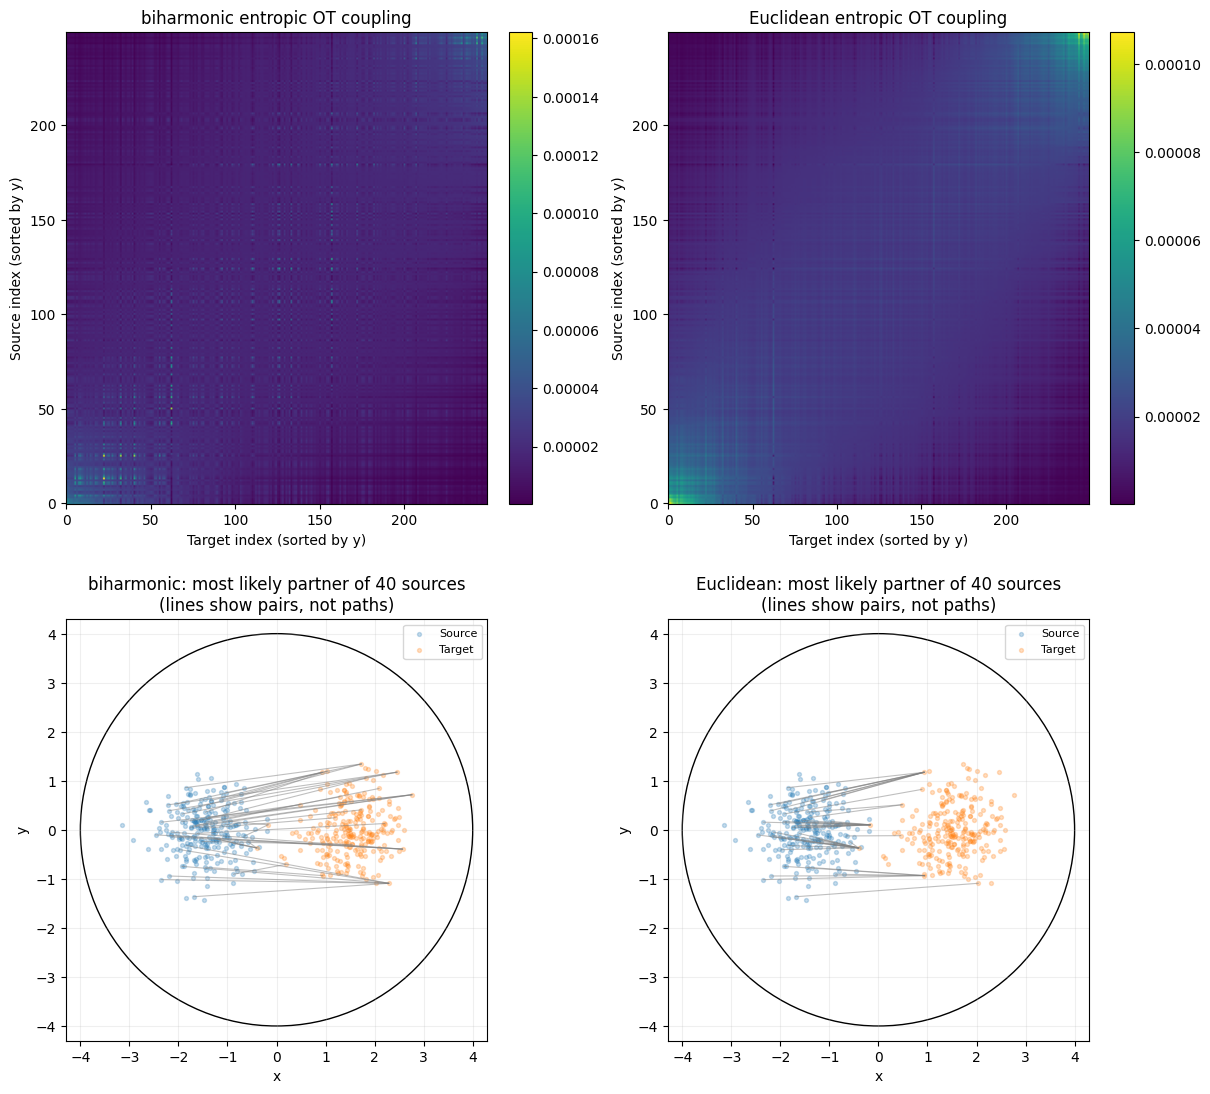

In [4]:
ot_epsilon = 0.05
match_biharmonic = flows.make_entropic_match_fn(ot_epsilon, embed=embed)
match_euclidean = flows.make_entropic_match_fn(ot_epsilon)
cost_matrices = {
    "biharmonic": cdist(np.asarray(embed(jnp.asarray(source))), np.asarray(embed(jnp.asarray(target)))),
    "Euclidean": cdist(source, target),
}
couplings = {
    "biharmonic": np.asarray(jax.jit(match_biharmonic)(source, target)),
    "Euclidean": np.asarray(jax.jit(match_euclidean)(source, target)),
}
# Reference only (not used for training): the squared Euclidean cost of standard OT-CFM.
squared_coupling = np.asarray(match_linear(
    jnp.asarray(source), jnp.asarray(target), cost_fn=costs.SqEuclidean(), epsilon=ot_epsilon,
    scale_cost="mean", tau_a=1.0, tau_b=1.0, threshold=1e-5, max_iterations=5000,
))
reference_couplings = {**couplings, "squared Euclidean (reference)": squared_coupling}

coupling_df = comparison.coupling_comparison_table(
    reference_couplings, cost_matrices, source, target, pair_masks=disc.pair_masks(source, target)
)
residuals = np.linalg.norm((target[None, :, :] - source[:, None, :]) - translation, axis=-1)
coupling_df["translation_residual"] = [
    np.sum(coupling * residuals) / coupling.sum()
    for coupling in [*reference_couplings.values(), np.ones_like(residuals)]
]
display(coupling_df)
comparison.plot_coupling_comparison(disc, couplings, source, target, seed=2026)

## Training: Riemannian vs. Euclidean FM × biharmonic vs. Euclidean couplings

All four models share the network, optimizer, batch size 32, 300 iterations and seed of the other toy notebooks. The RFM models integrate the biharmonic RFM field in 32 Euler steps with disc projection and velocity clipping at 30; the FM models use the zero-noise straight path $x_t=(1-t)x_0+tx_1$, $u_t=x_1-x_0$.

| | Biharmonic coupling | Euclidean coupling |
| --- | --- | --- |
| **Riemannian FM** (`otrfm`) | RFM + biharmonic OT | RFM + Euclidean OT |
| **Euclidean FM** (`otfm`) | FM + biharmonic OT | FM + Euclidean OT |

Training losses regress different velocity targets and are not comparable across interpolation types.

In [5]:
num_iterations, batch_size, seed = 300, 32, 2026
target_key, condition = "translated_gaussian", "translated Gaussian"
adata = flows.make_toy_adata(source, target, target_key)

rfm_cf = flows.prepare_toy_model(
    adata, "otrfm", target_key, **flows.DEFAULT_ARCHITECTURE,
    match_fn=match_biharmonic, nystroem=nystroem, optimizer=optax.adam(1e-3),
    solver_kwargs={"interpolation_steps": 32, "projection_fn": disc.project,
                   "project_to_manifold": False, "max_velocity_norm": 30.0},
    seed=seed,
)


def membership(cloud):
    # The clouds can overlap in x, so check membership instead of a coordinate threshold.
    return lambda cells: (np.abs(cells[:, None, :] - cloud[None]).max(axis=-1) < 1e-6).any(axis=1)


def build(solver, match_fn):
    model = flows.build_matched_model(rfm_cf, adata, solver, match_fn, target_key, seed,
                                      nystroem=nystroem if solver == "otrfm" else None)
    flows.check_source_target_split(model, batch_size, seed, membership(source), membership(target))
    return model


flows.check_source_target_split(rfm_cf, batch_size, seed, membership(source), membership(target))
models = {
    "RFM + biharmonic OT": rfm_cf,
    "RFM + Euclidean OT": build("otrfm", match_euclidean),
    "FM + biharmonic OT": build("otfm", match_biharmonic),
    "FM + Euclidean OT": build("otfm", match_euclidean),
}
colors = dict(zip(models, ["tab:green", "tab:cyan", "tab:purple", "tab:pink"], strict=True))
losses, training_seconds = {}, {}
display(comparison.train_untrained(models, losses, training_seconds, num_iterations, batch_size))

[                                        ] | 0% Completed | 221.99 us

[########################################] | 100% Completed | 101.94 ms

[                                        ] | 0% Completed | 194.41 us

[########################################] | 100% Completed | 101.67 ms

[                                        ] | 0% Completed | 189.81 us

[########################################] | 100% Completed | 101.65 ms

... (734 outputs left out)

 81%|████████  | 242/300 [00:00<00:00, 617.62it/s, loss=0.364]

100%|██████████| 300/300 [00:00<00:00, 517.79it/s, loss=0.364]

FM + Euclidean OT: 0.6s; mean loss first 25 2.11126, last 25 0.34964


,training_seconds,mean_loss_first_25,mean_loss_last_25
RFM + biharmonic OT,319.975001,3.956313,1.085904
RFM + Euclidean OT,306.257151,3.862848,1.035818
FM + biharmonic OT,10.765581,2.144704,0.381952
FM + Euclidean OT,0.580631,2.111261,0.349643


[                                        ] | 0% Completed | 239.91 us

[########################################] | 100% Completed | 101.53 ms

[                                        ] | 0% Completed | 142.55 us

[########################################] | 100% Completed | 101.35 ms

[                                        ] | 0% Completed | 185.57 us

[########################################] | 100% Completed | 102.77 ms

... (7 outputs left out)

[########################################] | 100% Completed | 102.50 ms

[                                        ] | 0% Completed | 183.36 us

[########################################] | 100% Completed | 101.76 ms

,energy_distance_squared,mean_error_to_target,outside_disc_fraction,mean_disc_violation,max_disc_violation,mean_displacement_error
unchanged source,4.326029,2.975681,0.0,0.0,0.0,NaN
RFM + biharmonic OT,0.026785,0.123386,0.0,0.0,0.0,0.141503
RFM + Euclidean OT,0.018494,0.105574,0.0,0.0,0.0,0.104998
FM + biharmonic OT,0.007253,0.083834,0.0,0.0,0.0,0.052991
FM + Euclidean OT,0.011774,0.123506,0.0,0.0,0.0,0.092387


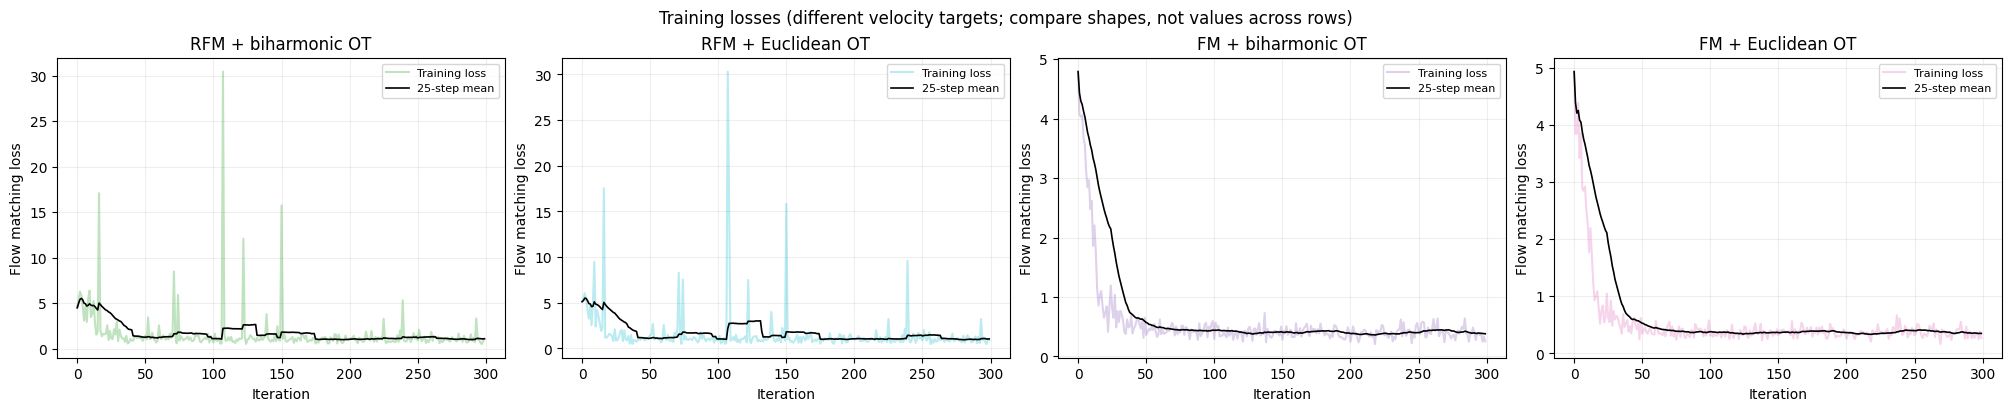

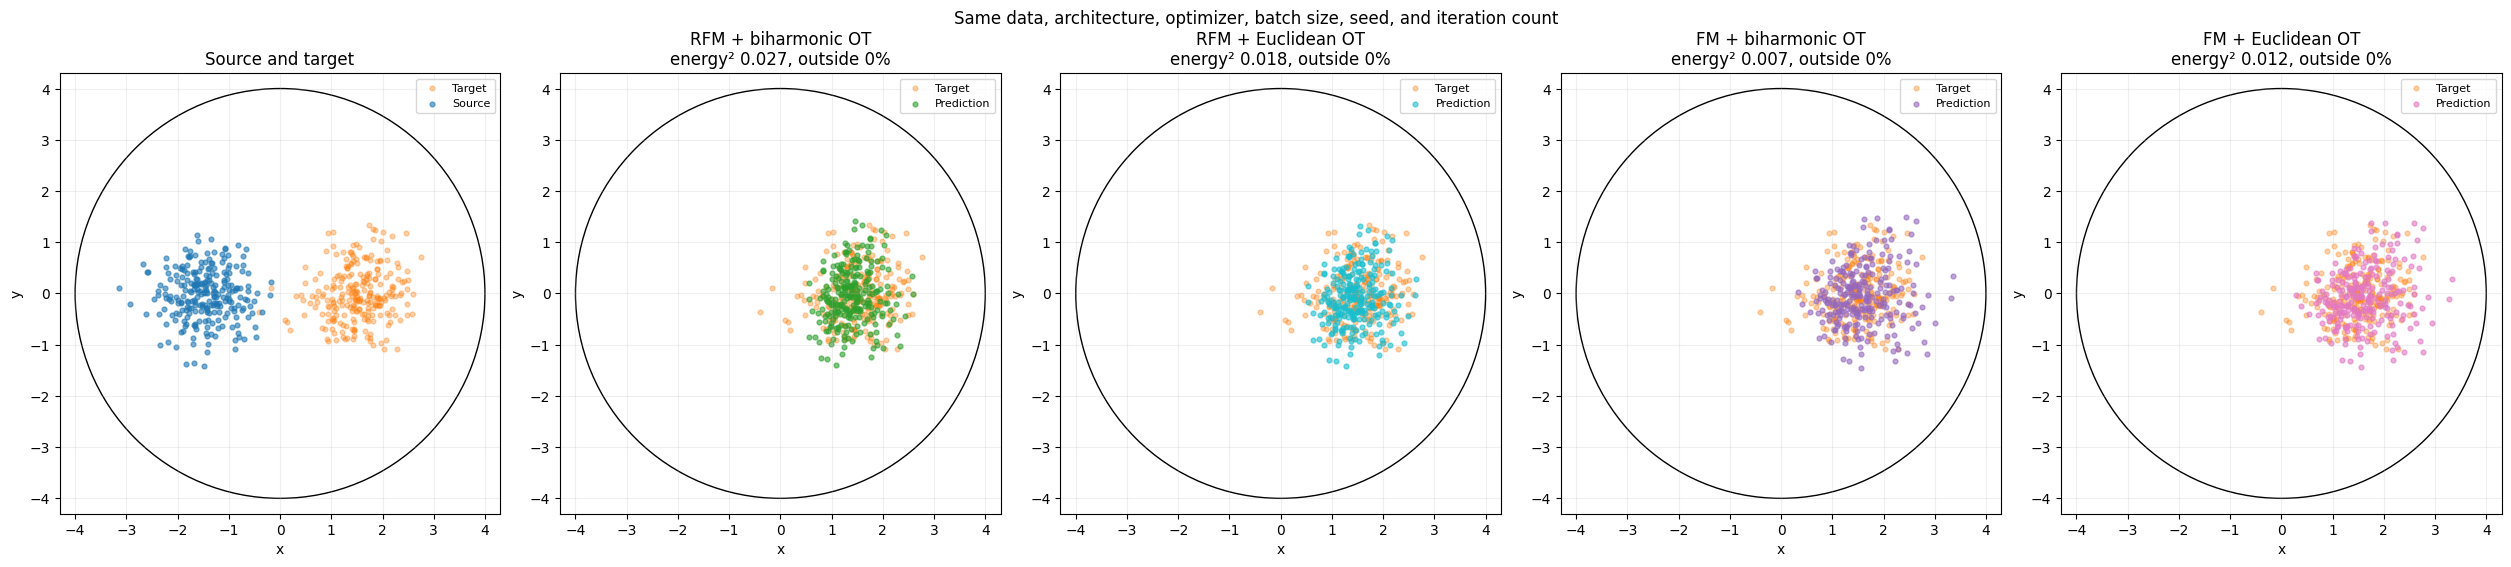

In [6]:
predicted = {name: flows.predict_target(model, adata, target_key, condition) for name, model in models.items()}
endpoint_df = comparison.endpoint_table(predicted, source, target, disc)
# Predictions are pushed from the fitted source cloud, so the mean displacement shows the learned translation.
endpoint_df["mean_displacement_error"] = [np.nan] + [
    float(np.linalg.norm((samples - source).mean(axis=0) - translation)) for samples in predicted.values()
]
display(endpoint_df)
plotting.plot_loss_panels(losses, colors, "Training losses (different velocity targets; compare shapes, not values across rows)")
plotting.plot_prediction_panels(disc, source, target, predicted, colors, metrics=endpoint_df)

### Learned fields and paths

The field panels share the grid, arrow scale (`arrow_dt` times velocity) and speed colors. The query point is the source mean at $t=0.5$, where the ideal field is the constant translation velocity $(3, 0)$. The paths start from 12 fresh source samples and integrate each learned field with the Tsit5 settings of `predict`. `mean_straightness` is chord length over path length, 1 for straight paths.

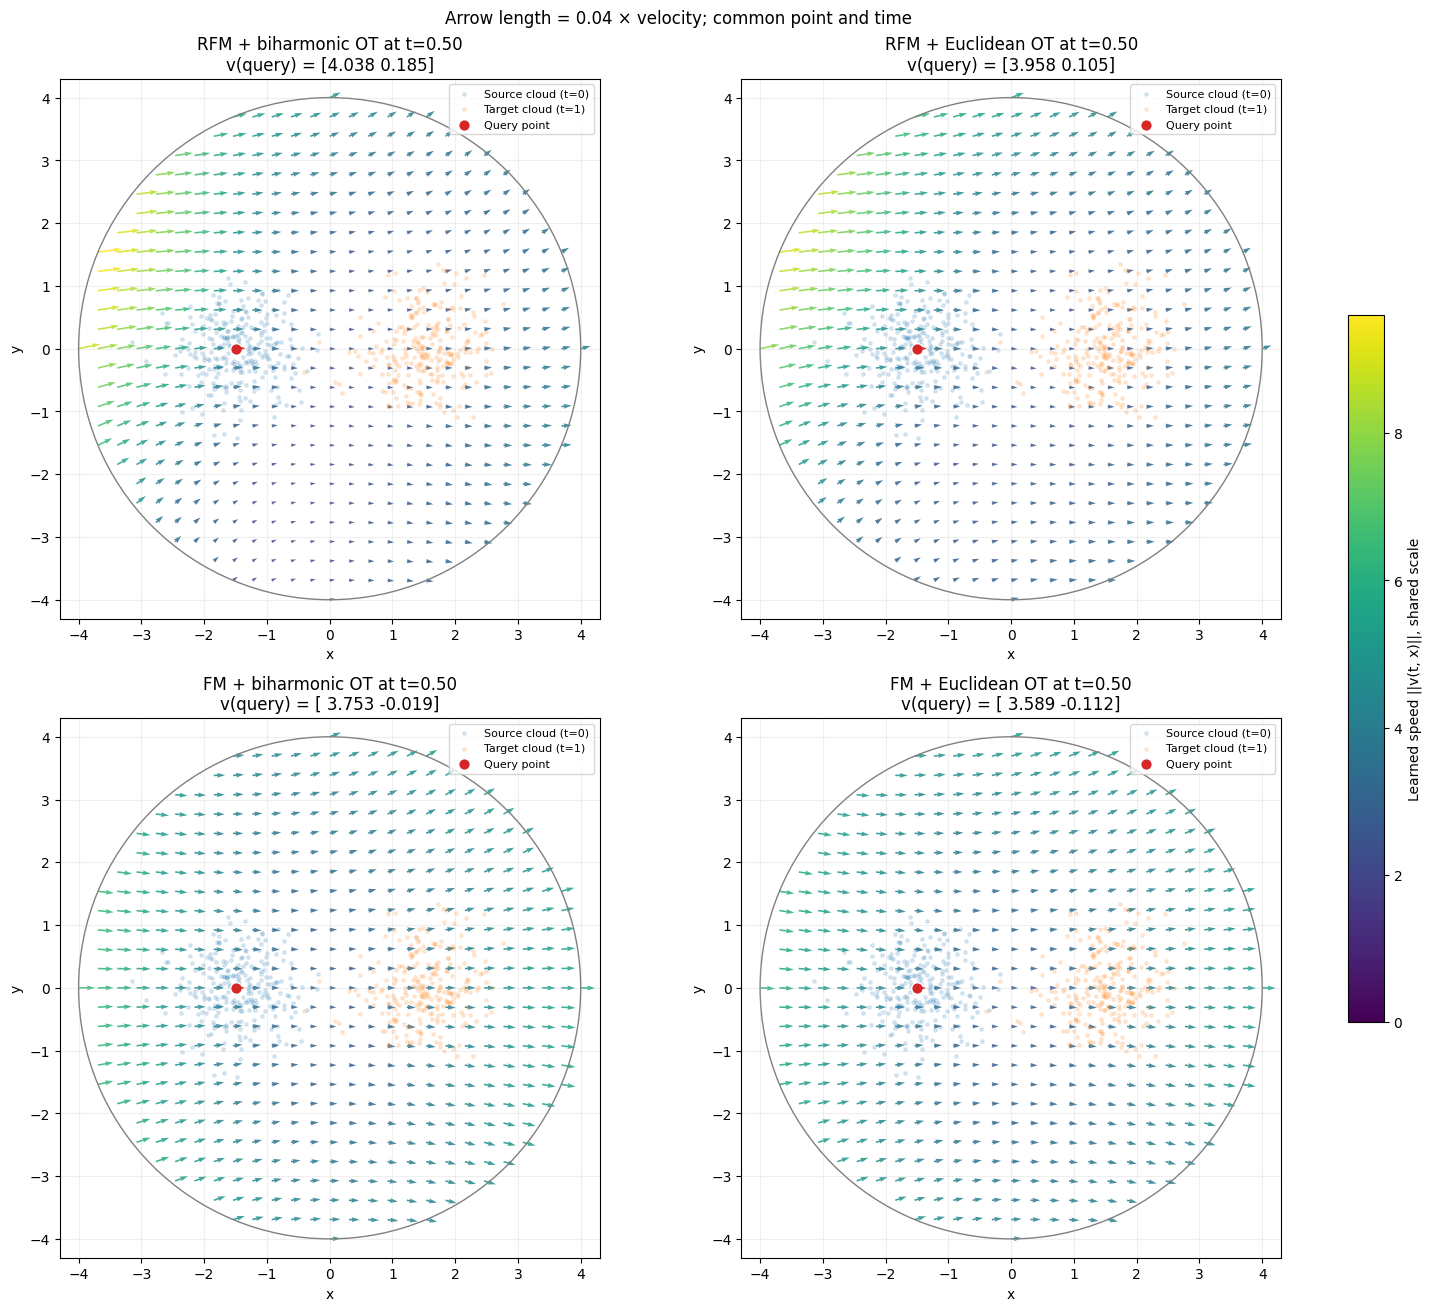

,query_vx,query_vy,query_speed,error_to_translation
RFM + biharmonic OT,4.037910,0.185396,4.042163,1.054338
RFM + Euclidean OT,3.957771,0.104875,3.959160,0.963496
FM + biharmonic OT,3.753247,-0.019097,3.753295,0.753489
FM + Euclidean OT,3.588906,-0.111803,3.590647,0.599425


In [7]:
query_point, query_time = mean_source.astype(np.float32), 0.5
fields = plotting.plot_field_comparison(disc, models, query_point, query_time, source, target, arrow_dt=0.04)
display(pd.DataFrame([values[-1] for values in fields.values()], index=list(fields), columns=["query_vx", "query_vy"])
        .assign(query_speed=lambda df: np.hypot(df["query_vx"], df["query_vy"]),
                error_to_translation=lambda df: np.hypot(df["query_vx"] - translation[0], df["query_vy"] - translation[1])))

,paths_leaving_disc,max_sampled_radius,mean_path_length,mean_straightness,max_step_length,max_disc_violation,mean_adaptive_solver_steps,mean_displacement_error
model,,,,,,,,
RFM + biharmonic OT,0,2.625870,2.884989,0.998668,0.030078,0.0,864.000000,0.171222
RFM + Euclidean OT,0,2.646818,2.943385,0.998538,0.028574,0.0,877.500000,0.153589
FM + biharmonic OT,0,3.246636,3.036163,0.999050,0.024366,0.0,711.166667,0.118402
FM + Euclidean OT,0,3.151308,3.045789,0.999335,0.022542,0.0,702.000000,0.129497


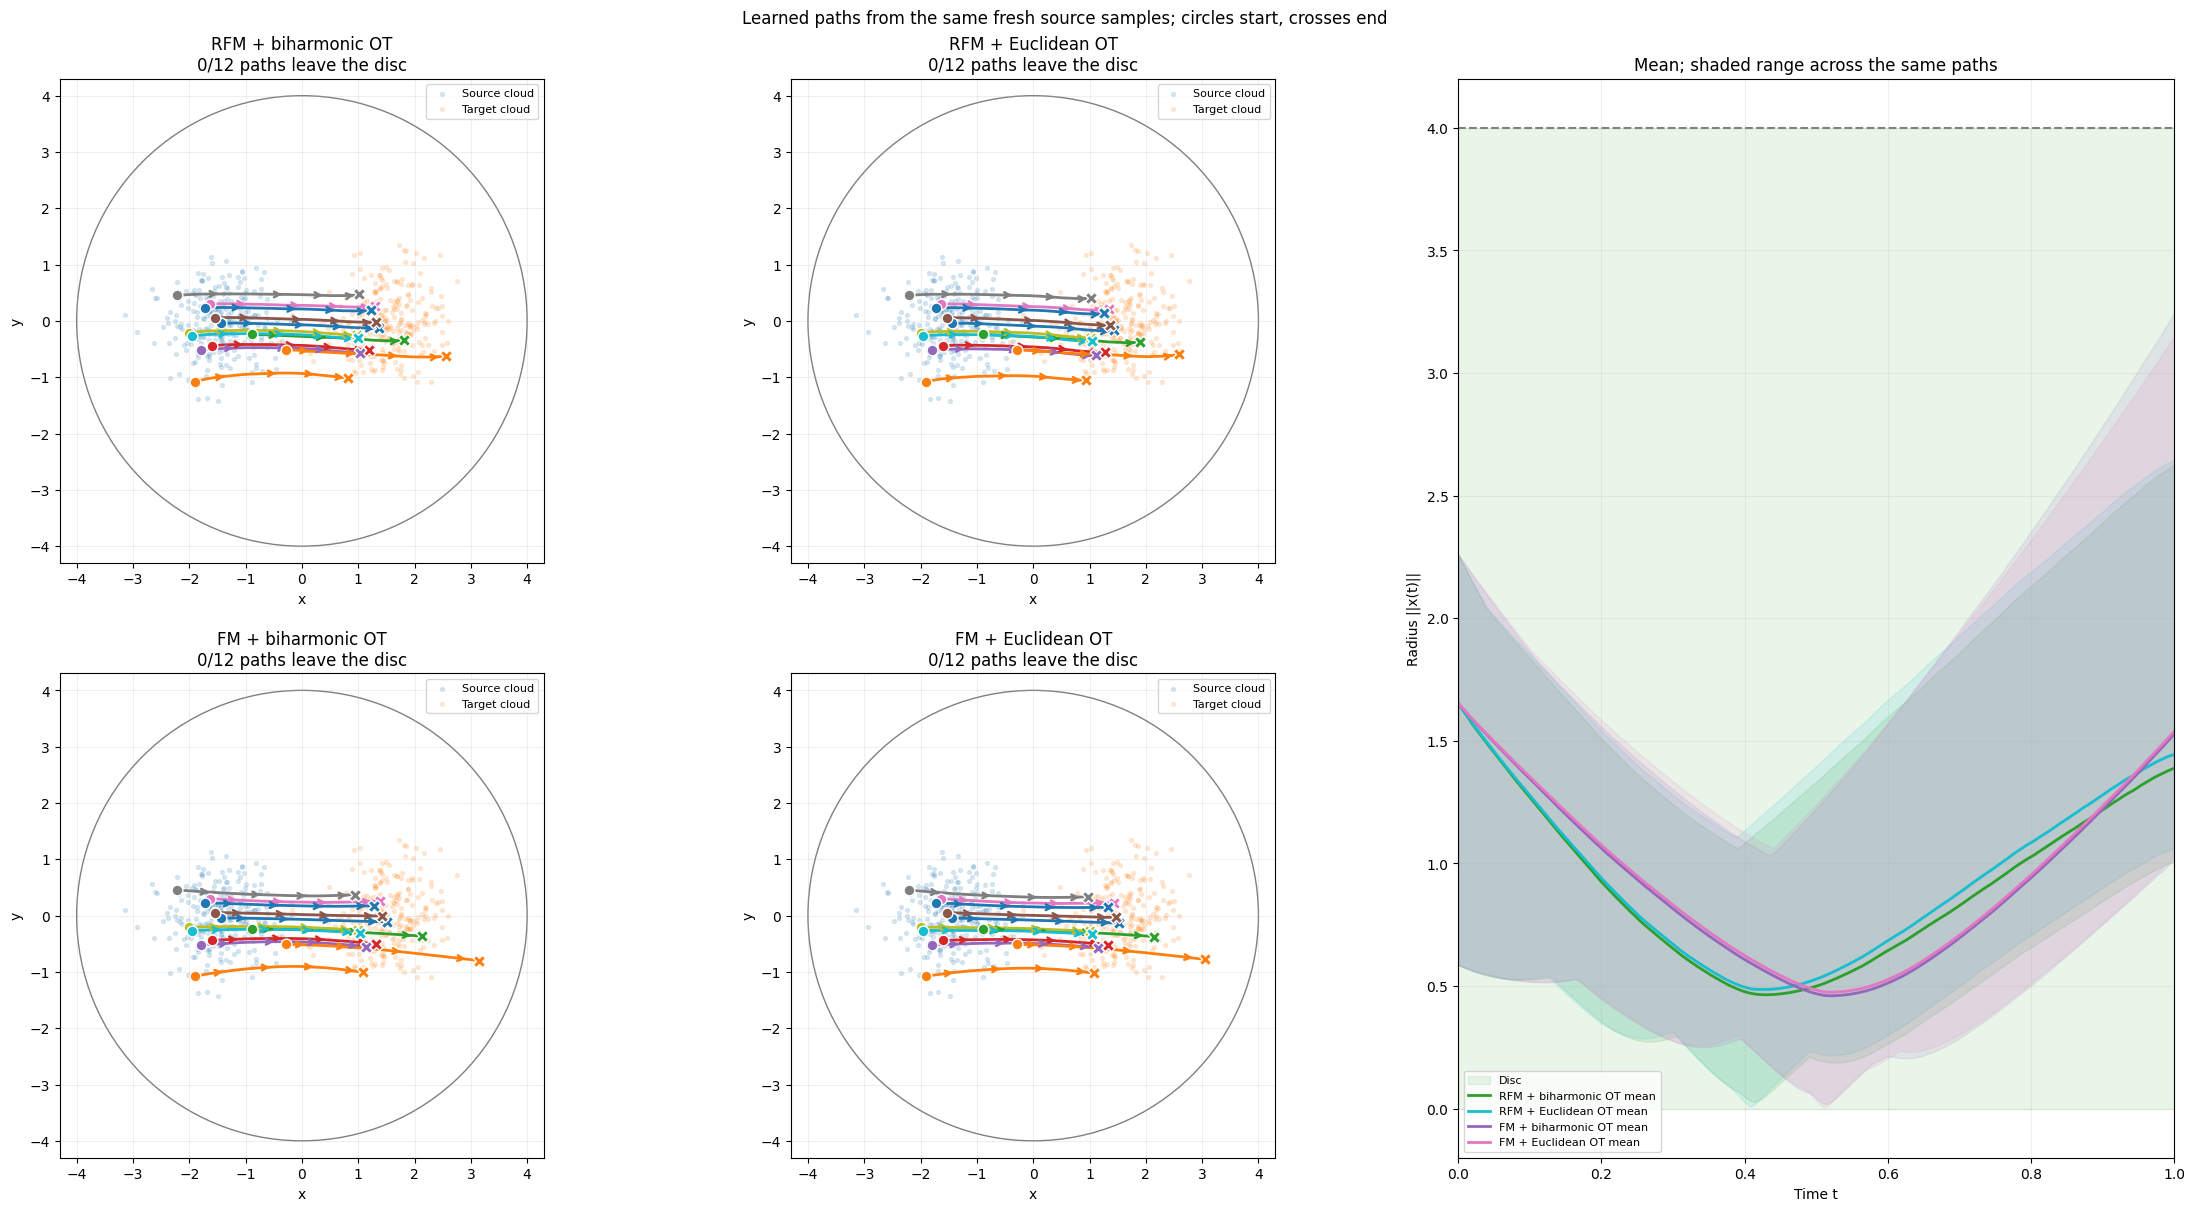

In [8]:
fresh_starts = disc.sample_gaussian(mean_source, variance, 12, np.random.default_rng(2027))[0].astype(np.float32)
path_times = np.linspace(0.0, 1.0, 201, dtype=np.float32)
trajectories, solver_steps = comparison.integrate_all_paths(models, fresh_starts, path_times)
path_df = comparison.path_table(disc, trajectories, solver_steps)
# Ideal transport moves every start by exactly the translation.
path_df["mean_displacement_error"] = [
    float(np.linalg.norm(paths[:, -1] - paths[:, 0] - translation, axis=1).mean()) for paths in trajectories.values()
]
display(path_df)
plotting.plot_path_comparison(disc, trajectories, path_times, source, target, colors, path_metrics=path_df)

energy_distance_squared  mean_error_to_target  \
interpolation coupling                                                       
RFM           biharmonic OT                 0.026785              0.123386   
              Euclidean OT                  0.018494              0.105574   
FM            biharmonic OT                 0.007253              0.083834   
              Euclidean OT                  0.011774              0.123506   

                             mean_straightness  mean_displacement_error  \
interpolation coupling                                                    
RFM           biharmonic OT           0.998668                 0.171222   
              Euclidean OT            0.998538                 0.153589   
FM            biharmonic OT           0.999050                 0.118402   
              Euclidean OT            0.999335                 0.129497   

                             training_seconds  
interpolation coupling                         
RFM           biharmonic OT        319.975001  
              Euclidean OT         306.257151  
FM            biharmonic OT         10.765581  
              Euclidean OT           0.580631

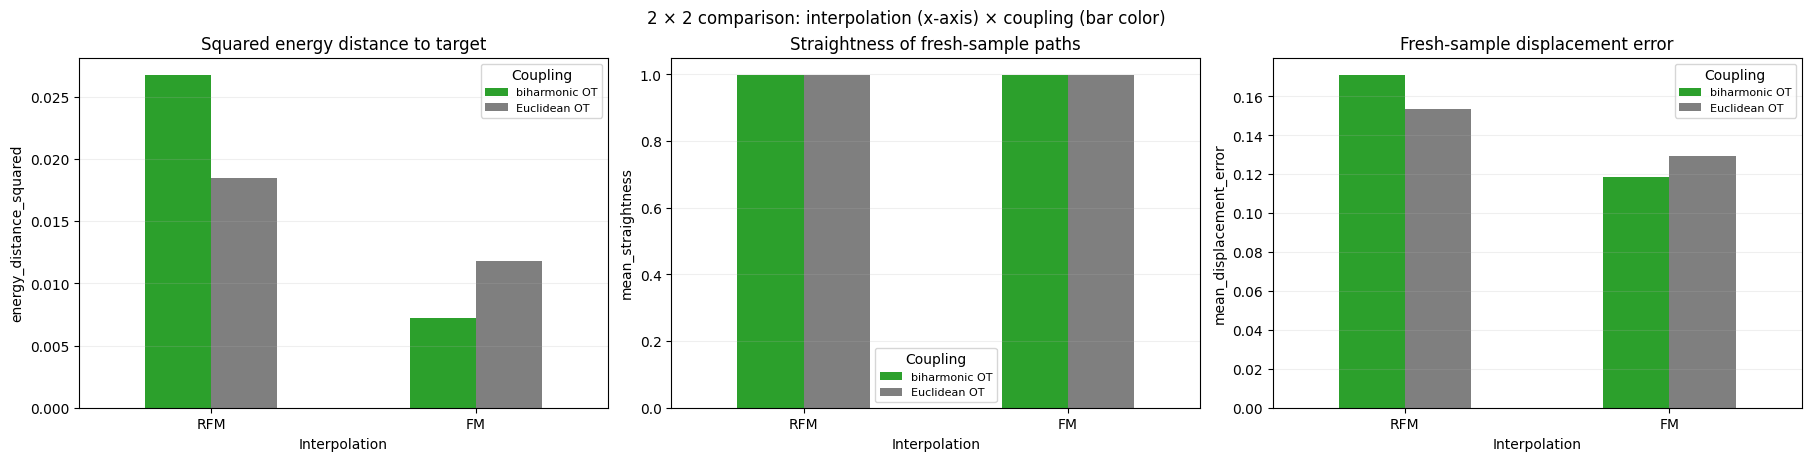

In [9]:
summary = comparison.factor_summary(
    endpoint_df, path_df, training_seconds, models,
    endpoint_columns=["energy_distance_squared", "mean_error_to_target"],
    path_columns=["mean_straightness", "mean_displacement_error"],
)
display(summary)
comparison.plot_factor_bars(summary, [
    ("energy_distance_squared", "Squared energy distance to target"),
    ("mean_straightness", "Straightness of fresh-sample paths"),
    ("mean_displacement_error", "Fresh-sample displacement error"),
])

## Conditional reference paths vs. straight-line geodesics

The networks regress conditional reference fields along reference paths from $x_0$ to $x_1$. On the disc, the exact geodesic is the straight chord at constant speed, which is exactly the FM reference path; FM therefore has zero distance to the geodesic by construction. The RFM reference paths integrate the biharmonic RFM field with the training interpolator (32 steps, disc projection, clipping) and, to separate the field from its discretization, with 512 steps. The curve distances are those of the annulus notebook: Hausdorff (worst deviation), Chamfer (typical deviation), time-parameterized $W_2$ (shape and speed profile) and arc-length $W_2$ (shape only).

In [10]:
ref_n_pairs, ref_fine_steps = 256, 512
ref_rng = np.random.default_rng(seed + 7)
ref_training_steps = rfm_cf.solver.interpolation_steps
ref_interpolator = loss_modes.interpolator_like(rfm_cf, nystroem)
ref_names = ["FM (straight line)", f"RFM ({ref_training_steps} steps, training)", f"RFM ({ref_fine_steps} steps)"]
ref_colors = dict(zip(ref_names, ["tab:pink", "tab:green", "tab:olive"], strict=True))

ref_pairs, ref_paths, ref_per_pair = {}, {}, {}
for name, coupling in couplings.items():
    x0, x1 = ref_pairs[f"{name} OT"] = reference_paths.sample_coupled_pairs(coupling, source, target, ref_n_pairs, ref_rng)
    fine_times, fine_paths = reference_paths.rfm_reference_paths(ref_interpolator, x0, x1, ref_fine_steps)
    ref_paths[f"{name} OT"] = {
        ref_names[0]: (fine_times, reference_paths.fm_reference_paths(x0, x1, fine_times)),
        ref_names[1]: reference_paths.rfm_reference_paths(ref_interpolator, x0, x1, ref_training_steps),
        ref_names[2]: (fine_times, fine_paths),
    }
    for ref_name, (times, paths) in ref_paths[f"{name} OT"].items():
        ref_per_pair[f"{name} OT", ref_name] = reference_paths.compare_to_geodesics(disc, x0, x1, times, paths)

ref_summary = reference_paths.summarize(ref_per_pair)
display(ref_summary.T.style.format("{:.3f}", na_rep="–"))

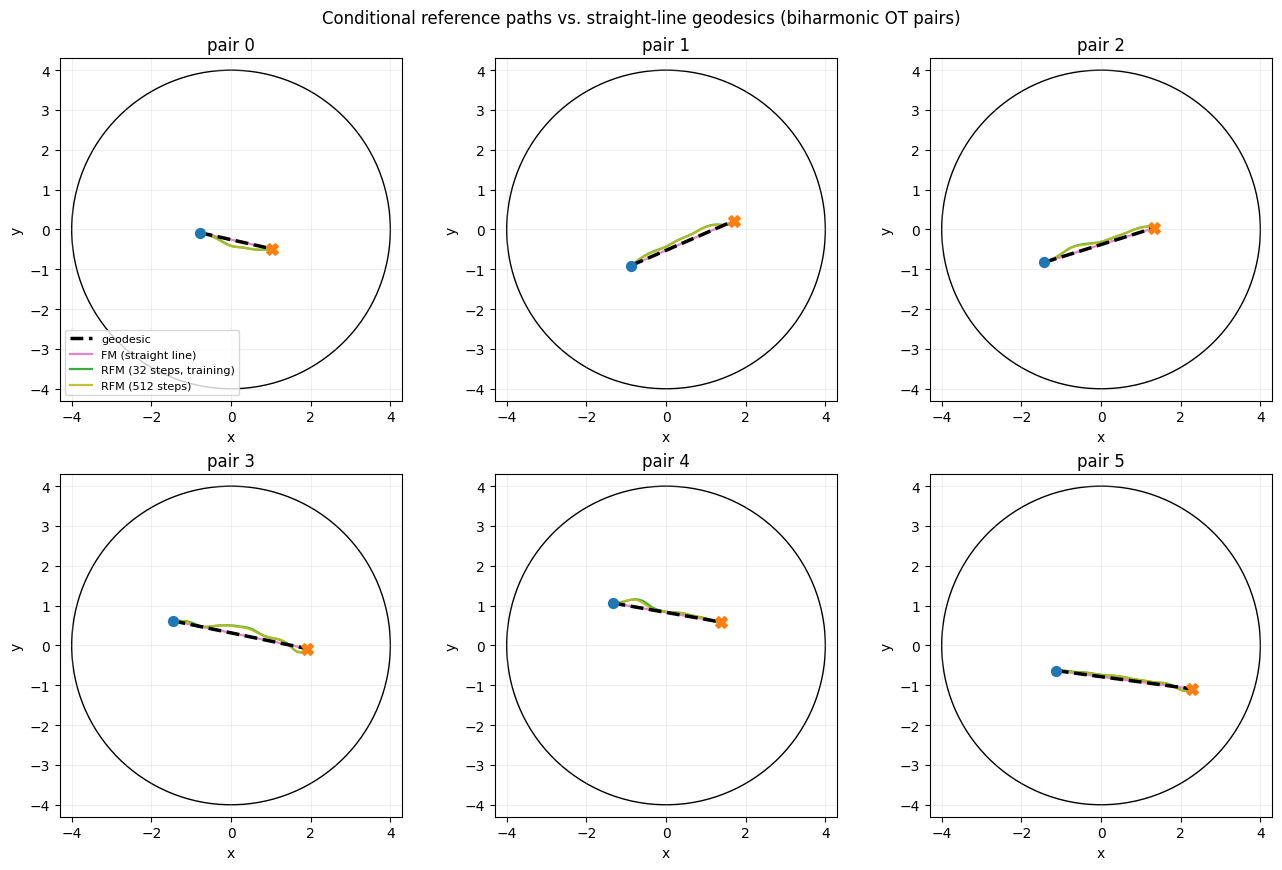

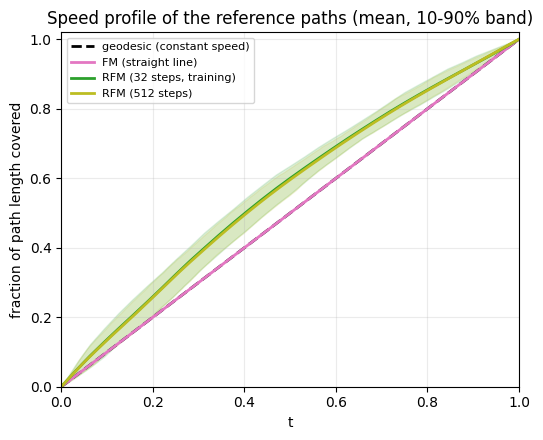

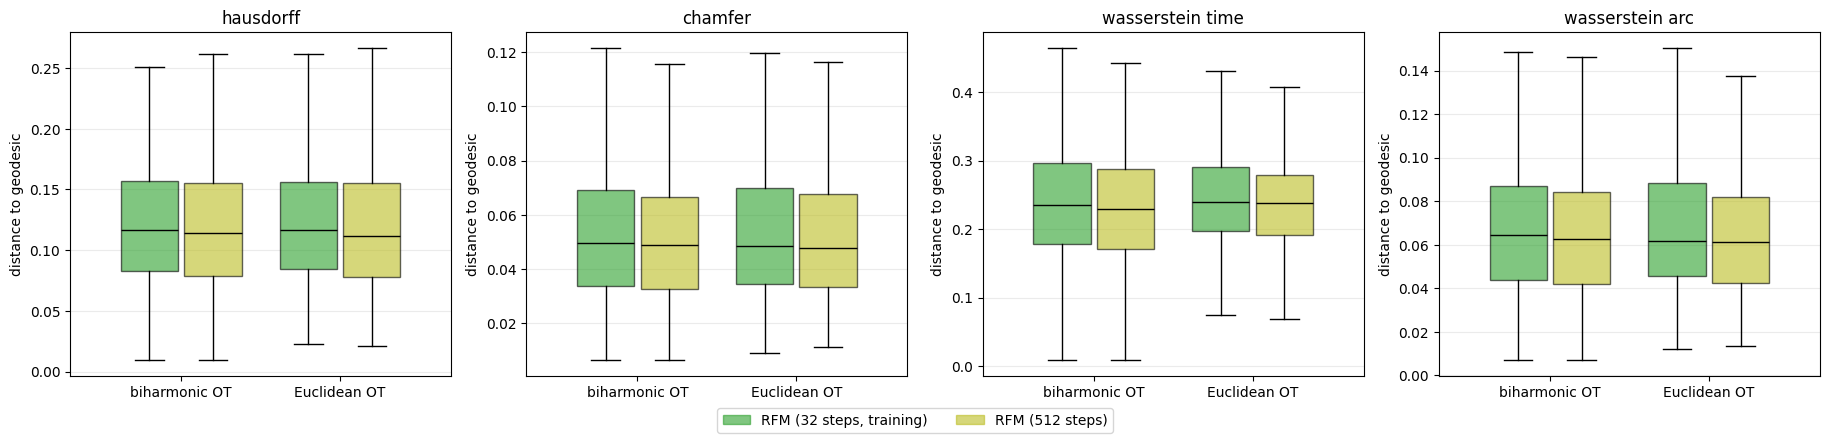

In [11]:
reference_paths.plot_reference_paths(
    disc, *ref_pairs["biharmonic OT"],
    {name: paths for name, (_, paths) in ref_paths["biharmonic OT"].items()},
    ref_colors, np.linspace(0.0, 1.0, 400), np.arange(6),
    title="Conditional reference paths vs. straight-line geodesics (biharmonic OT pairs)",
)
reference_paths.plot_arc_progress(ref_paths["biharmonic OT"], ref_colors)
reference_paths.plot_distance_distributions(
    {key: frame for key, frame in ref_per_pair.items() if not key[1].startswith("FM")},
    {name: color for name, color in ref_colors.items() if not name.startswith("FM")},
)

## Reading the results

Numbers are from the saved run (seed 2026, 300 iterations). They describe this one deterministic toy run, so rerun and recheck them after changing the kernel, $\varepsilon$, the interpolation resolution or the training length.

- **The biharmonic geometry is close to flat, but not exactly.** On pairs from the two clouds, the biharmonic distance follows the Euclidean one up to a scale factor, but it saturates for large distances (pairs more than about 3.5 apart lie below the diagonal). Near the source, the raw RFM field towards $x_1=(1.5,0)$ deviates from the straight direction by 9° (median) and 18° (90th percentile). Towards the boundary circle the deviation grows to 30–60°, so the bounded domain bends the field there. At $t=0$ the field is about 1.45 times faster than the straight field $x_1-x$ near the source.
- **Unsquared OT costs barely see the translation.** Both training couplings are nearly independent: `translation_residual` is 0.85 (biharmonic) and 0.79 (Euclidean), against 0.90 for the independent coupling. The squared Euclidean reference reaches 0.55 at the same relative $\varepsilon$. The biharmonic coupling is even closer to independent than the Euclidean one, because the saturation of the biharmonic distance flattens its cost further. Every model in the 2 × 2 grid is therefore trained on almost random pairs, and none of them learns the pure translation. Even FM matches the ideal velocity $(3,0)$ at the source mean only to within 0.6–0.75.
- **RFM matches FM but does not beat it.** All four models move the source onto the target (squared energy distance 0.007–0.027, down from 4.33), and no path leaves the disc. Both FM models do somewhat better than both RFM models: energy distance 0.007/0.012 vs. 0.027/0.018, and fresh-sample displacement error 0.12/0.13 vs. 0.17/0.15. The differences are small next to the spread of the clouds ($\sigma=0.5$). RFM training takes about 30 times longer (about 310 s vs. 11 s and 0.6 s) because every training step integrates the RFM interpolation. The coupling effect is not consistent: it changes sign between RFM and FM.
- **RFM reference paths are nearly straight, but front-loaded in time.** FM reference paths coincide with the geodesics by construction. The RFM paths stay within about 0.12 of the straight chord (median Hausdorff 0.11–0.12, Chamfer 0.05), are only 1.6–1.9 % longer, and refining from 32 to 512 Euler steps hardly changes them. The deviations are small wiggles, which come from the field and not from the discretization. The time-parameterized $W_2$ (0.23–0.25) is about 3.5 times the arc-length $W_2$ (0.07), because RFM covers 60 % of the path by $t=0.5$ instead of 50 %. Following the annulus notebook, this is the speed profile in which the *biharmonic* distance to $x_1$ shrinks linearly in $t$, while that distance grows sub-linearly with Euclidean distance. The learned RFM paths inherit the timing: their mean radius reaches its minimum near $t\approx0.43$, against $t\approx0.5$ for FM. The 32-step training paths end 0.014 short of $x_1$ on average; with 512 steps the gap is 0.001.

**Bottom line.** Without geometry, RFM with a well-resolved graph reproduces straight-line transport closely, but not exactly: it adds a small shape bias and a clear time reparameterization at about 30 times the training cost. Its endpoint quality is slightly below FM in this run. The coupling, not the interpolation, dominates the remaining error. A squared Euclidean (or squared biharmonic) cost would bring the couplings much closer to the exact translation.